# Plot treatment DEG Bootstrapping outputs
This notebook reads the outputs of the DEG trials and plots violin plots for genes of interest.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Load in the data and color map

In [2]:
input_file = "thc_1000_bootstrap_ttmt_aggregated.tsv"
df = pd.read_csv(input_file, sep="\t")

In [3]:
def read_colors(file):
    lines = None
    with open(file, "r") as f:
        lines = f.readlines()[1:]
    
    lines = {i.strip().split(",")[0]: i.strip().split(",")[1] for i in lines}
    return lines

In [4]:
cmap = read_colors("colors.csv")

## Make violin plots
Plot the violin plots of all of the genes in cell types in which they are significant.

/tmp/ipykernel_53890/468354822.py:28: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels([f"{label}\n{labs[label]}" for label in current_labels], rotation=45)


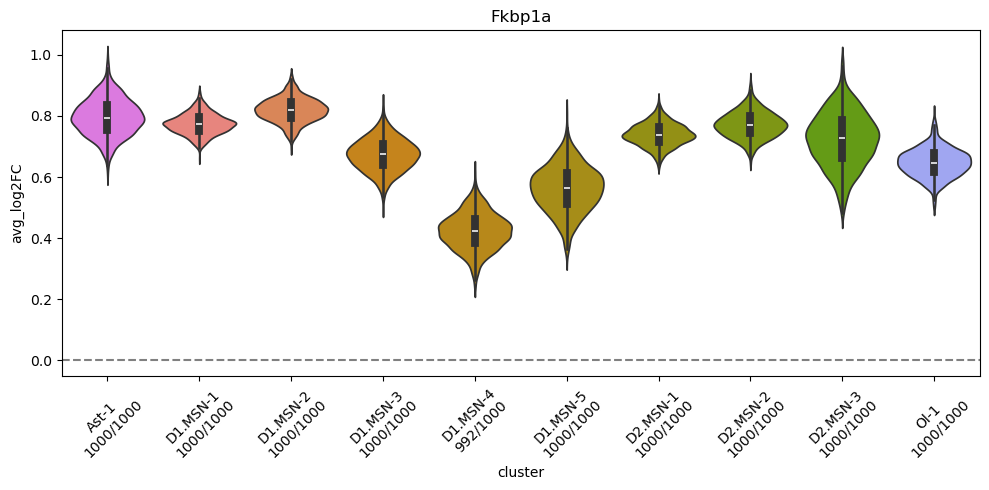

Done with Fkbp1a


/tmp/ipykernel_53890/468354822.py:28: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels([f"{label}\n{labs[label]}" for label in current_labels], rotation=45)


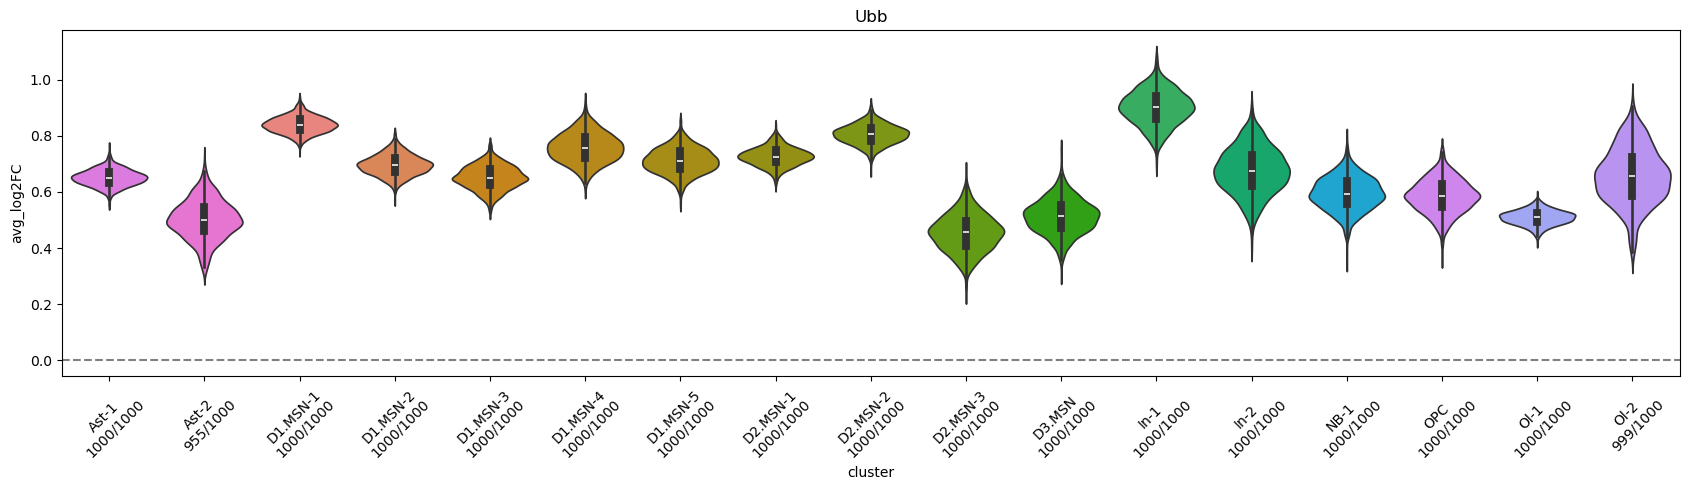

Done with Ubb


/tmp/ipykernel_53890/468354822.py:28: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels([f"{label}\n{labs[label]}" for label in current_labels], rotation=45)


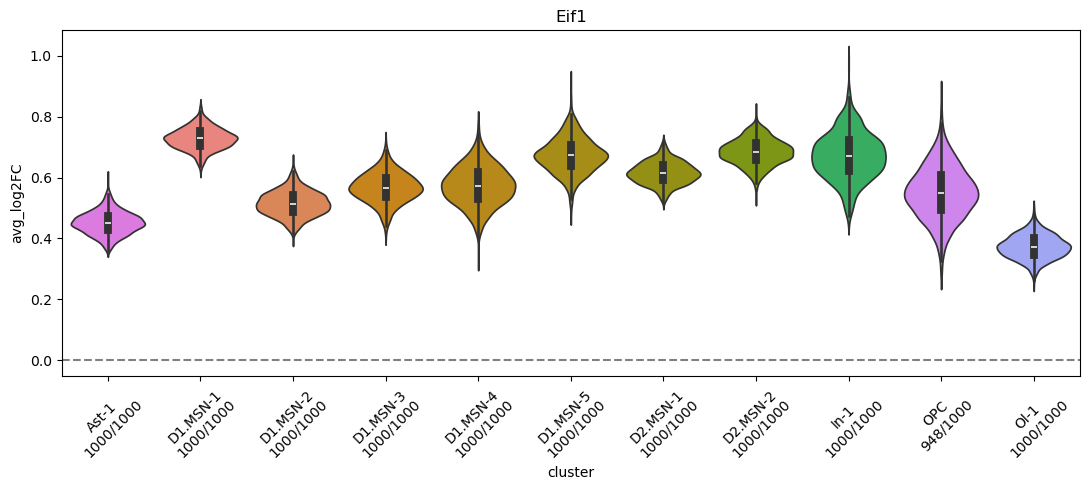

Done with Eif1


/tmp/ipykernel_53890/468354822.py:28: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels([f"{label}\n{labs[label]}" for label in current_labels], rotation=45)


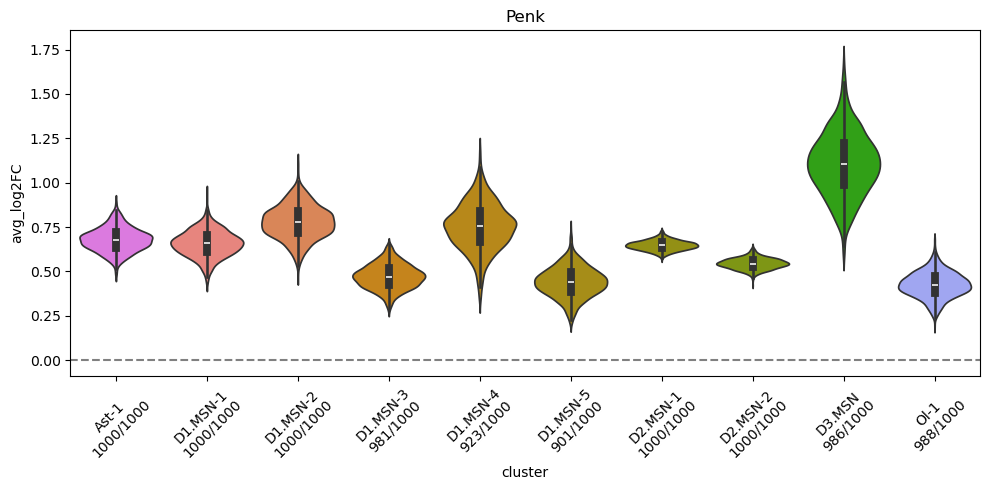

Done with Penk
Skipping Oprm1


/tmp/ipykernel_53890/468354822.py:28: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels([f"{label}\n{labs[label]}" for label in current_labels], rotation=45)


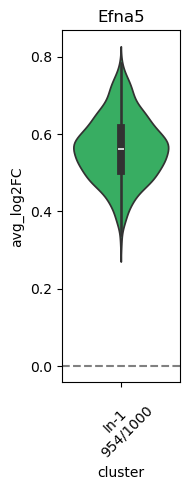

Done with Efna5


/tmp/ipykernel_53890/468354822.py:28: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels([f"{label}\n{labs[label]}" for label in current_labels], rotation=45)


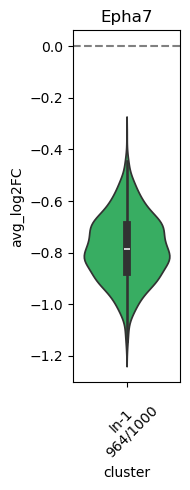

Done with Epha7
Skipping Epha10


/tmp/ipykernel_53890/468354822.py:28: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels([f"{label}\n{labs[label]}" for label in current_labels], rotation=45)


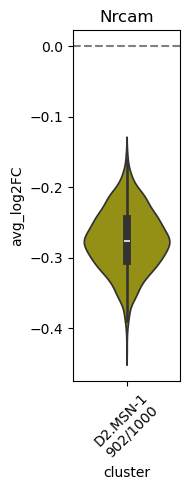

Done with Nrcam


/tmp/ipykernel_53890/468354822.py:28: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels([f"{label}\n{labs[label]}" for label in current_labels], rotation=45)


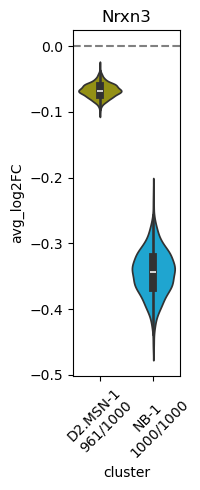

Done with Nrxn3


In [5]:
thc_genes = ["Fkbp1a", "Ubb", "Eif1", "Penk", "Oprm1", "Efna5", "Epha7", "Epha10", "Nrcam", "Nrxn3"]
# thc_genes = ["Efna5", "Epha7"]


for gene in thc_genes:
    subset = df[df["gene"] == gene]
    signif = subset[subset["p_val_adj"] < 0.05]
    sigs = list(signif["cluster"].unique())

    rm = set()
    labs = {}
    for s in sigs:
        ct = signif[signif["cluster"] == s].shape[0]
        tot_ct = subset[subset["cluster"] == s].shape[0]
        if (ct / tot_ct) < 0.9:
            rm.add(s)
        else:
            labs[s] = f"{ct}/{tot_ct}"

    sigs = list(set(sigs).difference(rm))
    sigs.sort()
    if len(sigs) > 0:
        plt.figure(figsize=(max(2,len(sigs)), 5))
        ax = sns.violinplot(subset[subset["cluster"].isin(sigs)], x="cluster",y="avg_log2FC", hue="cluster", palette=cmap, order=sigs)
        plt.axhline(y=0,linestyle="--", color="gray")
        ax.set_title(gene)
        current_labels = [tick.get_text() for tick in ax.get_xticklabels()]
        ax.set_xticklabels([f"{label}\n{labs[label]}" for label in current_labels], rotation=45)
        plt.tight_layout()
        plt.savefig(f"violins_filtered/violin_{gene}.pdf", bbox_inches="tight")
        plt.show()
        print("Done with "+ gene)
    else:
        print("Skipping "+ gene)
    